In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans

In [2]:
reg_szn = pd.read_csv("../../data/processed/reg-szn/player_data_merged.csv")
playoffs = pd.read_csv("../../data/processed/playoffs/player_data_merged.csv")

In [3]:
reg_szn.columns.tolist()

['adjusted-shooting_Rk',
 'Player',
 'adjusted-shooting_Age',
 'adjusted-shooting_Team',
 'adjusted-shooting_Pos',
 'adjusted-shooting_G',
 'adjusted-shooting_GS',
 'adjusted-shooting_MP',
 'adjusted-shooting_FG%',
 'adjusted-shooting_2P%',
 'adjusted-shooting_3P%',
 'adjusted-shooting_eFG%',
 'adjusted-shooting_FT%',
 'adjusted-shooting_TS%',
 'adjusted-shooting_FTr',
 'adjusted-shooting_3PAr',
 'adjusted-shooting_FG+',
 'adjusted-shooting_2P+',
 'adjusted-shooting_3P+',
 'adjusted-shooting_eFG+',
 'adjusted-shooting_FT+',
 'adjusted-shooting_TS+',
 'adjusted-shooting_FTr+',
 'adjusted-shooting_3PAr+',
 'adjusted-shooting_FG Add',
 'adjusted-shooting_TS Add',
 'adjusted-shooting_Awards',
 'player_id',
 'advanced_Rk',
 'advanced_Age',
 'advanced_Team',
 'advanced_Pos',
 'advanced_G',
 'advanced_GS',
 'advanced_MP',
 'advanced_PER',
 'advanced_TS%',
 'advanced_3PAr',
 'advanced_FTr',
 'advanced_ORB%',
 'advanced_DRB%',
 'advanced_TRB%',
 'advanced_AST%',
 'advanced_STL%',
 'advanced_BLK

In [4]:
#Individual datasets rather than the big one
reg_szn_shooting = pd.read_csv("../../data/basketball-reference/players(25-26)/regular-season/shooting.csv")
playoffs_shooting = pd.read_csv("../../data/basketball-reference/players(25-26)/playoffs/shooting.csv")

In [ ]:
# Determine what features we want to use for the K Means
X = reg_szn[['shooting_3P.1', 'shooting_2P.1', 'adjusted-shooting_TS%']]

# Scale features
X_Scaled = sklearn.preprocessing.StandardScaler().fit_transform(X)

# K Means & WCSS
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=0)
    kmeans.fit(X_Scaled)
    wcss.append(kmeans.inertia_)

ValueError: Input X contains NaN.
KMeans does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

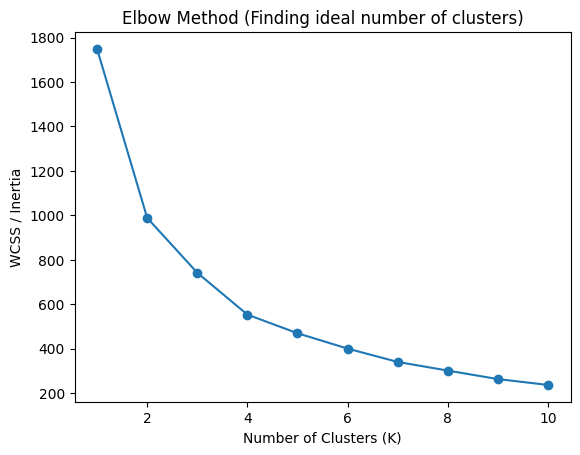

In [7]:
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method (Finding ideal number of clusters)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.show()

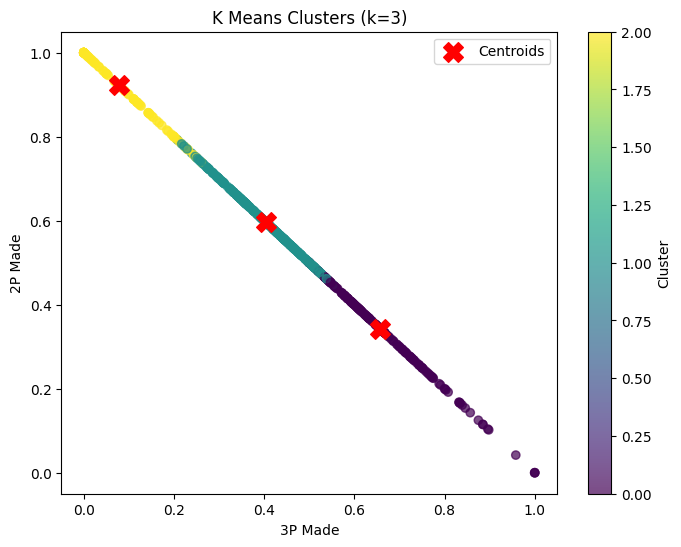

In [9]:
# Fit final K Means using the k chosen from the elbow plot
optimal_k = 3  # adjust based on where the elbow bends above

kmeans = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, n_init=10, random_state=0)
clusters = kmeans.fit_predict(X_Scaled)

# Inverse-transform centroids back to original units so they overlay on the raw scatter
scaler = sklearn.preprocessing.StandardScaler().fit(X)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X['shooting_3P'], X['shooting_2P'], c=clusters, cmap='viridis', alpha=0.7)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title(f'K Means Clusters (k={optimal_k})')
plt.xlabel('3P Made')
plt.ylabel('2P Made')
plt.legend()
plt.colorbar(scatter, label='Cluster')
plt.show()